数据的图形

1、类别数据的图形

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

df=pd.read_csv('shu4.csv')

df.describe()
df

,支出项目,北京,天津,上海,重庆
0,食品烟酒,9306.6,9138.4,12604.5,8154.5
1,衣着,2104.4,1872.0,2086.9,1708.3
2,居住,16846.7,7519.5,16136.8,4490.3
3,生活用品及服务,2559.7,1940.6,2248.1,1682.5
4,交通通信,4226.8,4390.4,5626.2,3049.8
5,教育文化娱乐,3348.0,3372.5,4709.9,2601.4
6,医疗保健,4285.7,3747.6,3877.9,2325.8
7,其他用品及服务,962.5,1207.5,1589.1,585.2


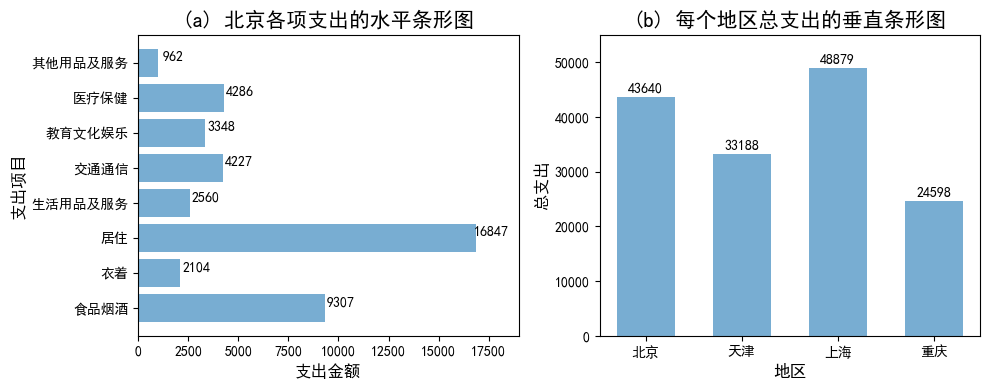

In [3]:
#（1）条形图
plt.rcParams['font.sans-serif'] = ['SimHei']   # 显示中文

# 图（a）北京各项支出的水平条形图
plt.subplots(1,2,figsize=(10,4))   # 设置子图和图形大小
plt.subplot(121)
plt.barh(y=df['支出项目'],width=df['北京'],alpha=0.6) # 绘制水平条形图
plt.xlabel('支出金额',size=12)
plt.ylabel('支出项目',size=12)
plt.title('(a) 北京各项支出的水平条形图',size=15)
plt.xlim(0,19000)          # 设置x轴的范围
# 为条形图添加标签（可根据需要选择）
x=df['北京']
y=df['支出项目']
for a,b in zip(x,y):plt.text(a+800, b, '%.0f'% a, # 标签位置在x值+800处
    ha='center', va='bottom',color='black',fontsize=10)

# 图（b）每个地区总支出的垂直条形图
plt.subplot(122)
labels= pd.Series(['北京','天津','上海','重庆']) 
h=[sum(df['北京']),sum(df['天津']),sum(df['上海']),sum(df['重庆'])]  # 各地区的总支出
plt.bar(x=labels,height=h,     # 绘制垂直条形图
        width=0.6,alpha=0.6,   # 设置条的宽度和颜色透明度
        align='center')# 默认align='center',x轴标签与条形中心对齐，'edge'表示x轴标签与条形左边缘对齐
plt.xlabel('地区',size=12)
plt.ylabel('总支出',size=12)
plt.title('(b) 每个地区总支出的垂直条形图',size=15)
plt.ylim(0,55000)              # 设置y轴范围
# 为条形图添加数值标签
x=labels;y=h
for a,b in zip(x,y):
    plt.text(a, b+500, '%.0f'% b, # 标签位置在y值+500处
    ha='center', va= 'bottom',color='black',fontsize=10)

plt.tight_layout()                # 紧凑布局
plt.show()

(2) 绘制帕累托图

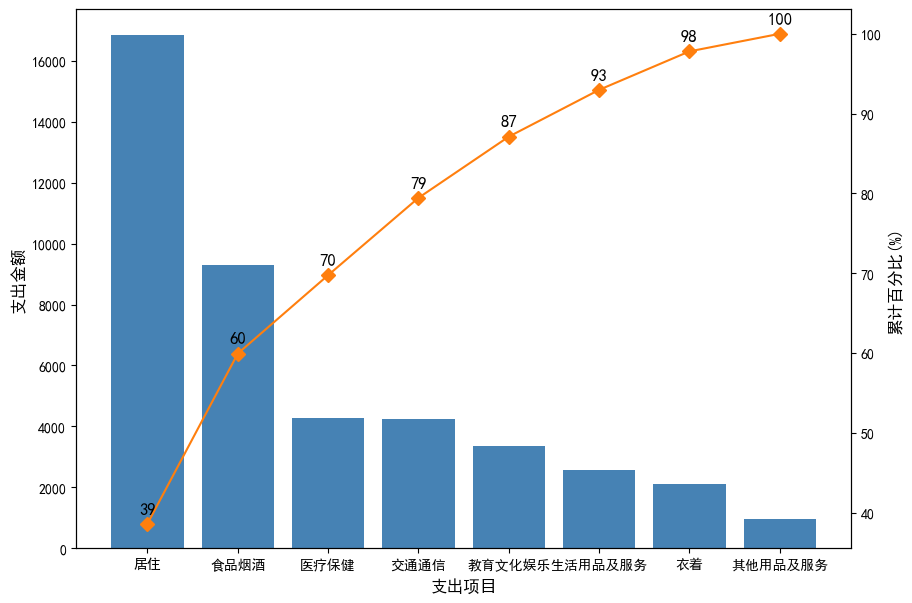

In [5]:
# 制帕累托图
plt.rcParams['font.sans-serif'] = ['SimHei']
# 处理数据
df=df.sort_values(by='北京', ascending=False)   # 按北京支出金额降序排序数据框
p = 100*df['北京'].cumsum()/df['北京'].sum()    # 计算累积百分比
df['累计百分比']=p                              # 在数据框中插入累计百分比列

# 绘制条形图
fig, ax = plt.subplots(figsize = (10,7))             # 设置子图和大小
ax.bar(df['支出项目'], df["北京"], color="steelblue")  # 绘制条形图
ax.set_ylabel('支出金额',size=12)                      # 设置y轴标签
ax.set_xlabel('支出项目',size=12)                      # 设置x轴标签
#plt.xticks(range(8),df['支出项目'],rotation=30)

ax2 = ax.twinx()                       # 与条形图共享坐标轴
ax2.plot(df['支出项目'], df["累计百分比"], color="C1", marker="D", ms=7) # 绘制折线图
ax2.set_ylabel('累计百分比(%)',size=12) # 设置y轴标签

# 添加标签
for a,b in zip(df['支出项目'],df['累计百分比']):
    plt.text(a, b+1, '%.0f'% b, # 标签位置在y值+1处
    ha='center', va= 'bottom',color='black',fontsize=12)
    
plt.show()

(3) 绘制并列条形图和堆叠条形图

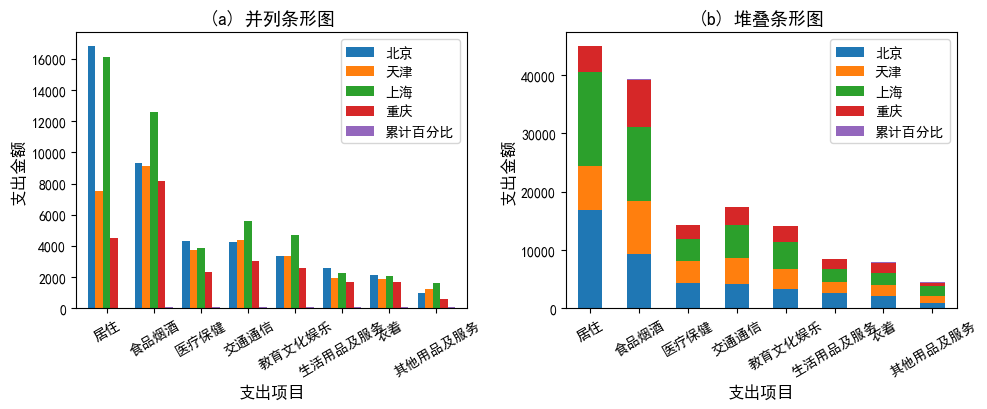

In [7]:
# 绘制并列条形图和堆叠条形图

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.subplots(1,2,figsize=(10,4.2))   # 设置子图和图形大小
# 并列条形图
ax1=plt.subplot(121)   # 设置子图1
df.plot(kind='bar',stacked=False,width=0.8,ax=ax1) # 绘制并列条形图
plt.xlabel('支出项目',size=12)
plt.ylabel('支出金额',size=12)
plt.xticks(range(8),df['支出项目'],rotation=30)  # 添加x轴标签并设置旋转角度
plt.title('(a) 并列条形图',fontsize=13,color='black')  
    
# 图（b）堆叠条形图
ax2=plt.subplot(122)   # 设置子图2
df.plot(kind='bar',stacked=True,width=0.5,ax=ax2) # 绘制堆叠条形图
plt.xlabel('支出项目',size=12)
plt.ylabel('支出金额',size=12)
plt.xticks(range(8),df['支出项目'],rotation=30)
plt.title('(b) 堆叠条形图',fontsize=13,color='black')

plt.tight_layout()     # 紧凑布局
plt.show()

（4） 绘制饼图和环形图

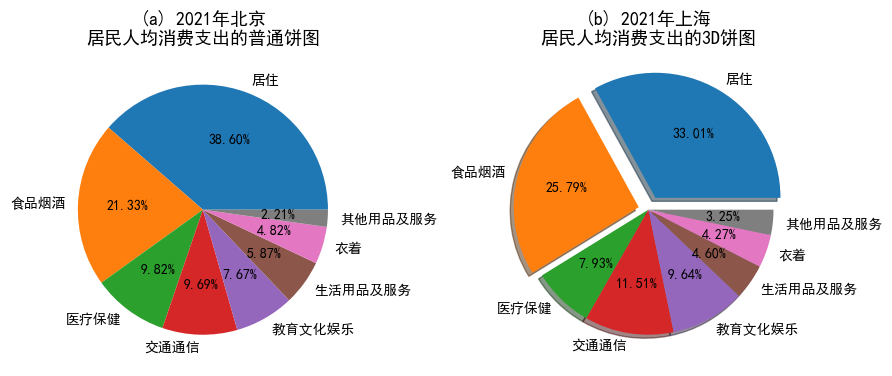

In [9]:
#绘制普通饼图和3D饼图
plt.rcParams['font.sans-serif'] = ['SimHei']
# 图（a）绘制普通饼图（以北京为例）
plt.subplots(1,2,figsize=(9,5))
plt.subplot(121)
p1=plt.pie(df['北京'],labels=df['支出项目'],
           autopct='%1.2f%%')  # 显示数据标签为百分比格式，%1.2f表示保留2位小数
plt.title('(a) 2021年北京\n居民人均消费支出的普通饼图',size=13)

# 图（b）绘制3D饼图（以上海为例）
plt.subplot(122)
p2=plt.pie(df['上海'],labels=df['支出项目'],autopct='%1.2f%%',
           shadow=True,                   # 绘制立体带阴影的饼图
           explode=(0.11,0.08,0,0,0,0,0,0))  # 设置某一块与中心的距离
plt.title('(b) 2021年上海\n居民人均消费支出的3D饼图',size=13)

plt.subplots_adjust(wspace=0.1)   #调整子图的间距
plt.tight_layout()
plt.show()


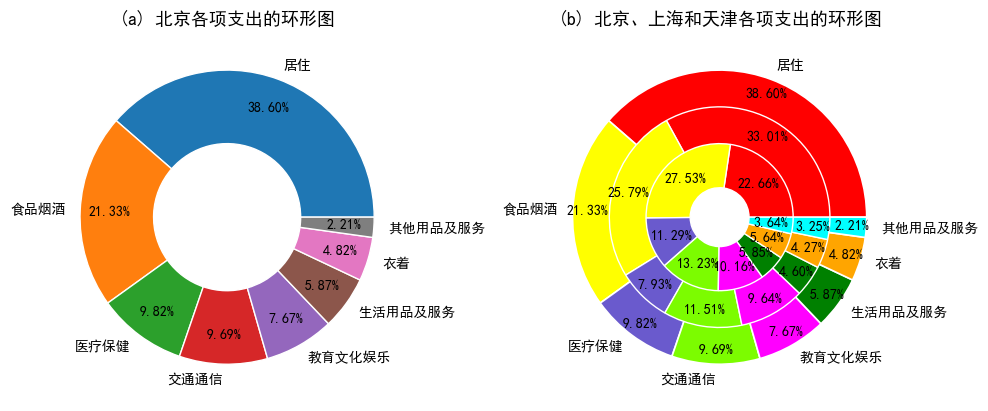

In [11]:
###  绘制环形图
plt.rcParams['font.sans-serif'] = ['SimHei']  # 显示中文
# 图（a） 绘制单样本环形图（以北京的各项支出为例）
plt.subplots(1,2,figsize=(10,8))
plt.subplot(121)
p1=plt.pie(df['北京'],labels=df['支出项目'],startangle=0,
           autopct='%1.2f%%',pctdistance=0.8,
           wedgeprops={'width':0.5,'edgecolor':'w'})  # 环的宽度为0.5，边线颜色为白色
plt.title('(a) 北京各项支出的环形图',size=13)

# 图（b） 绘制多样本嵌套环形图（以北京、上海和天津为例）
plt.subplot(122)
colors=['red','yellow','slateblue','lawngreen','magenta',
        'green','orange','cyan','pink','gold']  # 设置颜色向量
p2=plt.pie(df['北京'],labels=df['支出项目'],autopct='%1.2f%%',
           radius=1,pctdistance=0.9,    # 半径为1，标签距圆心距离
           colors=colors,
           wedgeprops=dict(linewidth=1.2,width=0.3,edgecolor='w'))

p3=plt.pie(df['上海'],autopct='%1.2f%%',
           radius=0.75,pctdistance=0.85,colors=colors,
           wedgeprops=dict(linewidth=1,width=0.3,edgecolor='w'))

p4=plt.pie(df['天津'],autopct='%1.2f%%',
           radius=0.5,pctdistance=0.7,colors=colors,
           wedgeprops=dict(linewidth=1,width=0.3,edgecolor='w'))
plt.title('(b) 北京、上海和天津各项支出的环形图',size=13)

plt.tight_layout()
plt.show()


## #   2、数据分布的图形

（1）绘制直方图

In [13]:
df=pd.read_csv('shu5.csv')
df.describe()
#df.info()
df

,日期,北京,上海,郑州,武汉,西安,沈阳
0,2022/1/1,52,68,92,128,114,66
1,2022/1/2,32,98,102,163,150,51
2,2022/1/3,50,97,147,134,169,57
3,2022/1/4,58,72,142,158,232,45
4,2022/1/5,84,41,175,49,254,107
...,...,...,...,...,...,...,...
360,2022/12/27,31,97,160,125,83,99
361,2022/12/28,36,105,160,169,78,54
362,2022/12/29,30,44,95,153,109,69
363,2022/12/30,48,68,193,129,165,89


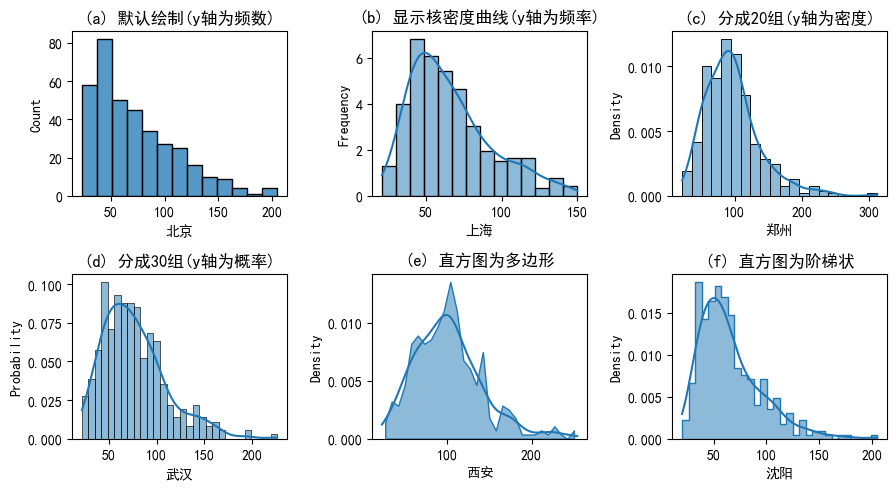

In [17]:
# （1）绘制直方图
import seaborn as sns
plt.rcParams['font.sans-serif'] = ['SimHei']

plt.subplots(2,3,figsize=(9,5))
plt.subplot(231)
sns.histplot(df['北京'],element='bars')  # 默认绘制，直方图为条形，y轴为计数（观测频数）
plt.title('(a) 默认绘制(y轴为频数)')

plt.subplot(232)
sns.histplot(df['上海'],kde=True,  # 显示核密度曲线
             stat='frequency')  # y轴为频率（观测频数除以箱宽，即频数除以组距）
plt.title('(b) 显示核密度曲线(y轴为频率)')  

plt.subplot(233)
sns.histplot(df['郑州'],bins=20,        # 分成20组（箱子个数）
             kde=True,stat= "density")  # y轴为密度（直方图的面积为1）
plt.title('(c) 分成20组(y轴为密度)')

plt.subplot(234)
sns.histplot(df['武汉'],bins=30,kde=True,stat="probability") # y轴为概率，条的高度之和为1
plt.title('(d) 分成30组(y轴为概率)')

plt.subplot(235)
sns.histplot(df['西安'],bins=30,kde=True,stat= "density",element='poly')# 直方图为多边形
plt.title('(e) 直方图为多边形')

plt.subplot(236)
sns.histplot(df['沈阳'],bins=30,kde=True,stat= "density",element='step')# 直方图为阶梯状
plt.title('(f) 直方图为阶梯状')

plt.tight_layout()
plt.show()

(2) 绘制核密度图

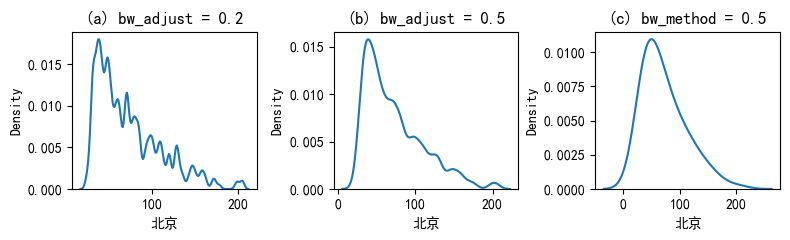

In [19]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns 

#绘制核密度图
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

#sns.set_style('darkgrid')  # 设置画图风格
plt.subplots(1,3,figsize=(8,2.5))

plt.subplot(131)
sns.kdeplot(df['北京'],bw_adjust=0.2)
plt.title('(a) bw_adjust = 0.2')

plt.subplot(132)
sns.kdeplot(df['北京'],bw_adjust=0.5)
plt.title('(b) bw_adjust = 0.5')

plt.subplot(133)
sns.kdeplot(df['北京'],bw_method=0.5)
plt.title('(c) bw_method = 0.5')

plt.subplots_adjust(wspace=0.5)   #调整子图的间距
plt.tight_layout()
plt.show()

### 绘制核密度图

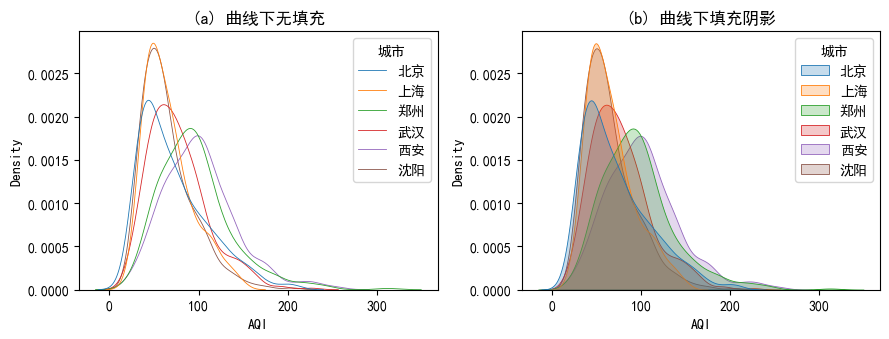

In [21]:
# 绘制核密度图
df=pd.read_csv('shu5.csv')


plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
df=pd.read_csv('shu5.csv')
df1= pd.melt(df, value_vars=['北京', '上海', '郑州','武汉','西安','沈阳'], 
             var_name='城市', value_name='AQI')  # 融合数据为长格式
# df1["城市"]=df1['城市'].astype(str)

plt.subplots(1,2,figsize=(9,3.5))
plt.subplot(121)
sns.kdeplot(df1,x='AQI',hue='城市',linewidth=0.6)  # 线宽=0.6
plt.title('(a) 曲线下无填充')

plt.subplot(122)
sns.kdeplot(df1,x='AQI',hue='城市',linewidth=0.6,fill=True) # alpha设置颜色透明度
plt.title('(b) 曲线下填充阴影')

plt.tight_layout()
plt.show()


### 绘制箱形图

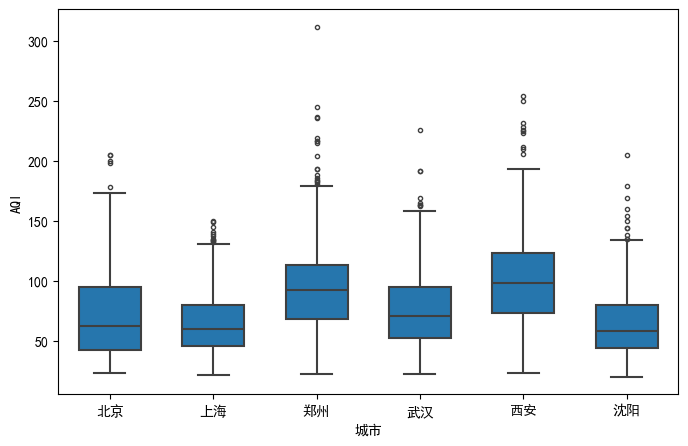

In [23]:
### 绘制箱形图
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

df1= pd.melt(df, value_vars=['北京', '上海', '郑州','武汉','西安','沈阳'], 
             var_name='城市', value_name='AQI')  # 融合数据
plt.figure(figsize=(8, 5))
sns.boxplot(data=df1,x='城市',y='AQI',
            width=0.6,linewidth=1.5,    # 设置箱子的宽度和线宽
            saturation=0.9,  # 设置颜色的原始饱和度比例。1表示完全饱和
            fliersize=3,     # 设置离群点标记的大小
            notch=False,     # 设置notch可绘制出箱子的凹槽

            orient="v")      # 如果变量是在行的位置，可设置orient="h",绘制水平箱线图

plt.show()



### 绘制小提琴图

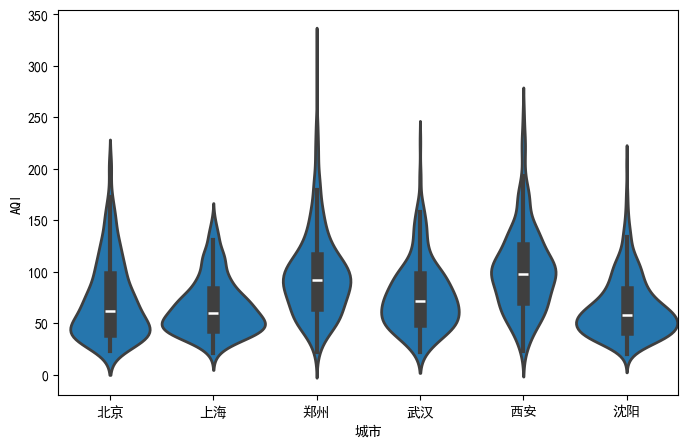

In [25]:
## 绘制小提琴图
df=pd.read_csv('shu5.csv')
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
#sns.set_style('darkgrid')

df1= pd.melt(df, value_vars=['北京', '上海', '郑州','武汉','西安','沈阳'], 
             var_name='城市', value_name='AQI')  # 融合数据

plt.figure(figsize=(8, 5))
sns.violinplot(data=df1,x='城市',y='AQI',
          
            width=1,linewidth=2,   # 设置小提琴的宽度和线宽
            saturation=0.9,  # 设置颜色饱和度，1表示完全饱和
            # fliersize=2,     # 设置离群点标记的大小
    
            orient="v",      # 绘制垂直小提琴图（默认）
            inner='box')     # 小提琴图内部绘制箱线图（默认）

plt.show()

3、变量间关系可视化

（1）绘制散点图

In [27]:
import pandas as pd
import matplotlib.pyplot as plt
df=pd.read_csv('shu6.csv')
df.describe()
df.info()
df

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31 entries, 0 to 30
Data columns (total 5 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   地区         31 non-null     object 
 1   地区生产总值     31 non-null     float64
 2   地方财政税收收入   31 non-null     float64
 3   社会消费品零售总额  31 non-null     float64
 4   年末总人口      31 non-null     int64  
dtypes: float64(3), int64(1), object(1)
memory usage: 1.3+ KB


,地区,地区生产总值,地方财政税收收入,社会消费品零售总额,年末总人口
0,北京,41045.6,5164.64,14867.7,2189
1,天津,15685.1,1621.89,3769.8,1373
2,河北,40397.1,2735.73,13509.9,7448
3,山西,22870.4,2094.72,7747.3,3480
4,内蒙古,21166.0,1671.05,5060.3,2400
5,辽宁,27569.5,1970.87,9783.9,4229
6,吉林,13163.8,809.41,4216.6,2375
7,黑龙江,14858.2,870.18,5542.9,3125
8,上海,43653.2,6606.74,18079.3,2489
9,江苏,117392.4,8171.30,42702.6,8505


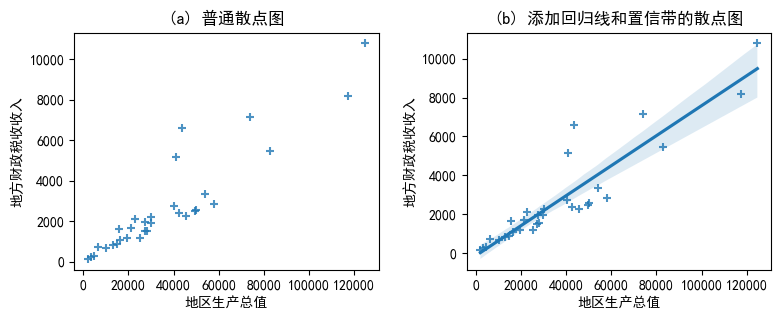

In [43]:
#（1）绘制散点图（函数sns.regplot）

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False
plt.subplots(1,2,figsize=(8, 3.3))
# （a）普通散点图
plt.subplot(121)
sns.regplot(x=df['地区生产总值'],y=df['地方财政税收收入'],
            fit_reg=False,marker='+',data=df)
plt.title('(a) 普通散点图')

# （b）添加回归线和置信带的散点图
plt.subplot(122)
sns.regplot(data=df,x=df['地区生产总值'],y=df['地方财政税收收入'],
            fit_reg=True,marker='+')   # 添加回归线
plt.title('(b) 添加回归线和置信带的散点图')

plt.tight_layout()
plt.show()

###绘制带有边际图的散点图

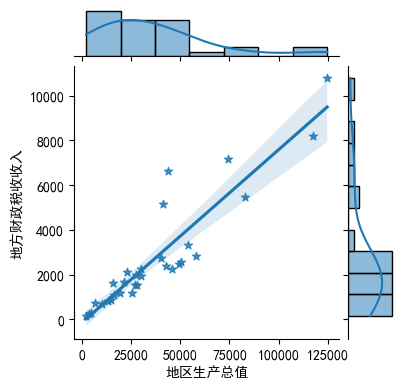

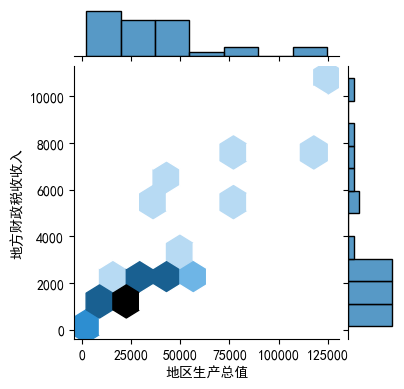

In [29]:
#绘制带有边际图的散点图
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False


# （a）绘制带回归线和置信带的散点图
sns.jointplot(data=df,x=df['地区生产总值'],y=df['地方财政税收收入'],marker='*',
              kind='reg',  # 绘制回归线和置信带
              height=4,    # 设置图形的高度（正方形）
              ratio=5)     # 设置主图高度与边际图高度的比

# （b）绘制六边形分箱散点图
sns.jointplot(data=df,x=df['地区生产总值'],y=df['地方财政税收收入'],
              kind='hex', height=4,ratio=5)

plt.show()



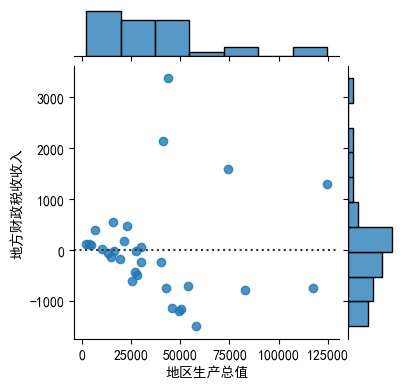

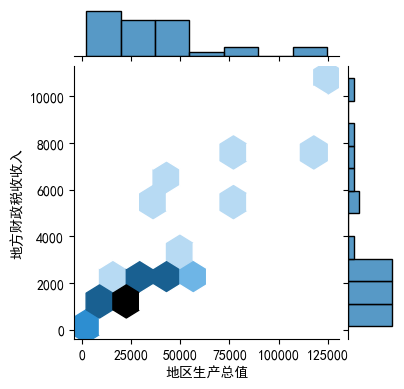

In [48]:
#绘制带有边际图的散点图
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False


# （a）绘制带回归线和置信带的散点图
sns.jointplot(data=df,x=df['地区生产总值'],y=df['地方财政税收收入'],
              kind='resid',  # 绘制回归线和置信带
              height=4,    # 设置图形的高度（正方形）
              ratio=5)     # 设置主图高度与边际图高度的比

# （b）绘制六边形分箱散点图
sns.jointplot(data=df,x=df['地区生产总值'],y=df['地方财政税收收入'],
              kind='hex', height=4,ratio=5)

plt.show()

### 绘制 散点图矩阵

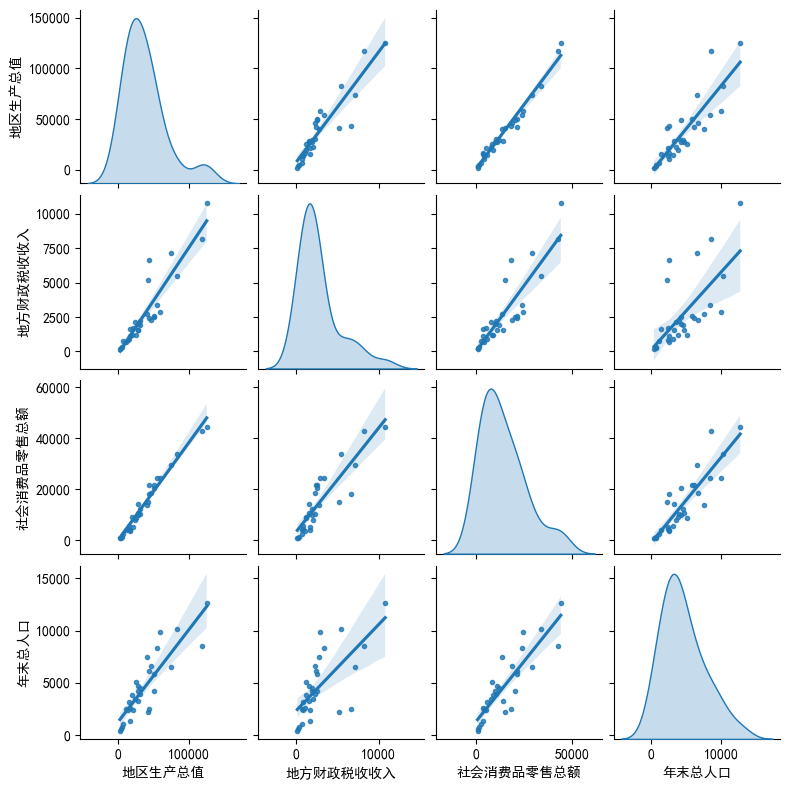

In [31]:
# 绘制 散点图矩阵
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False


sns.pairplot(df[['地区生产总值','地方财政税收收入','社会消费品零售总额','年末总人口']],
             height=2,           # 设置子图的高度
             diag_kind='kde',    # 设置对角线的图形类型（默认为直方图）
             markers='.',        # 设置点型
             kind='reg')         # 设置子图类型，默认为scatter

plt.show()


### 绘制相关系数矩阵

<Axes: >

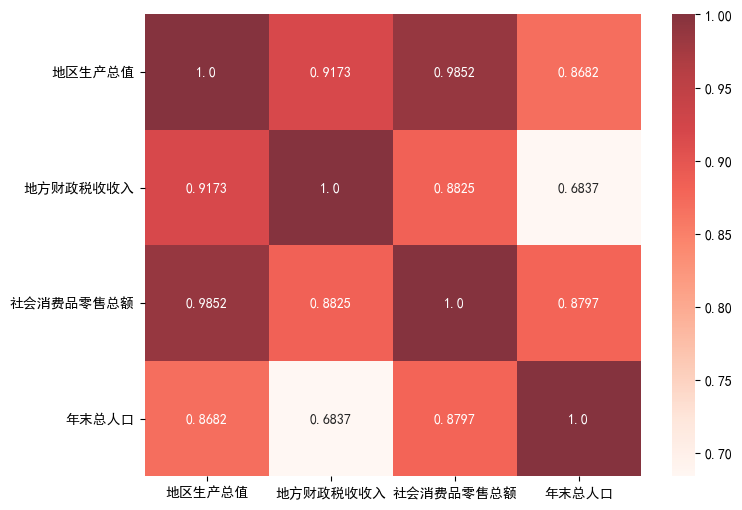

In [33]:
### 绘制 散点图矩阵制代码

plt.rcParams['font.sans-serif'] = ['SimHei']  # 显示中文
plt.rcParams['axes.unicode_minus'] = False    # 显示负号

plt.figure(figsize=(8, 6))     # 设置图形大小
corr=df.iloc[:,1:].corr()     # 计算相关系数矩阵 
sns.heatmap(corr,cmap='Reds',alpha=0.8, annot=True,fmt='.4')
                                   # 使用调色板'Reds',显示值，保留4位小数


### 三个变量之间的关系：3D散点图

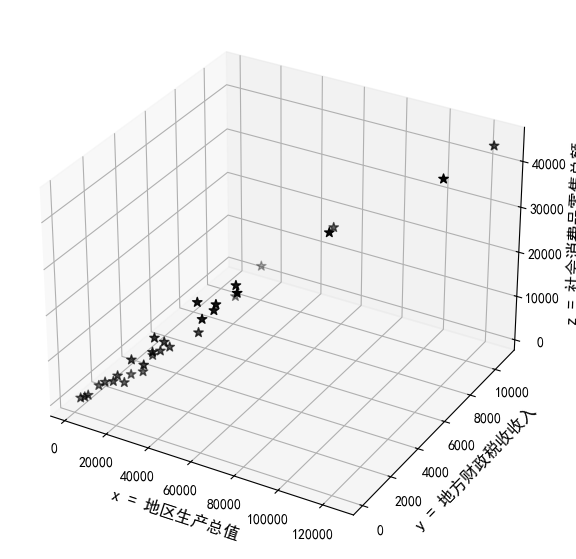

In [35]:
# 3D散点图
from mpl_toolkits.mplot3d import Axes3D
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

ax3d=plt.figure(figsize=(10, 7)).add_subplot(111,projection='3d')
ax3d.scatter(df['地区生产总值'],df['地方财政税收收入'],df['社会消费品零售总额'],
             color='black',marker='*',s=50)
ax3d.set_xlabel('x = 地区生产总值',fontsize=12)
ax3d.set_ylabel('y = 地方财政税收收入',fontsize=12)
ax3d.set_zlabel('z = 社会消费品零售总额',fontsize=12)

plt.show()

### 绘制气泡图

Text(0.5, 1.0, '社会消费品零售总额=气泡的大小')

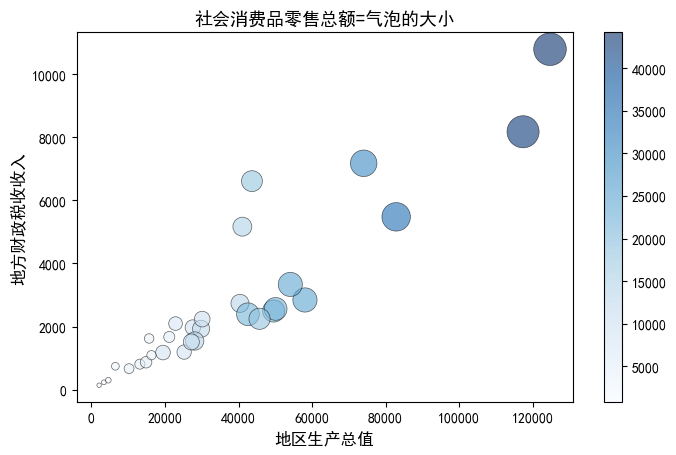

In [37]:
# 绘制气泡图

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(8, 4.8))
plt.scatter(data=df,x='地区生产总值',y='地方财政税收收入',
            c='社会消费品零售总额',            # 设置气泡变量
            s=df['社会消费品零售总额']/80,     # 设置气泡大小
            cmap='Blues',         # 设置调色板
            edgecolors='k',       # 设置气泡边线的颜色 
            linewidths=0.5,       # 设置气泡边线的宽度  
            alpha=0.6)            # 设置颜色透明度
plt.colorbar()   # 绘制表示总股本的颜色条（图例）

plt.xlabel('地区生产总值',fontsize=12)
plt.ylabel('地方财政税收收入',fontsize=12)
plt.title('社会消费品零售总额=气泡的大小',fontsize=13)


4、 样本相似性图

### 绘制平行坐标图

([<matplotlib.axis.XTick at 0x18404eb7e00>,
 [Text(0, 0, '食品烟酒'),
  Text(1, 0, '衣着'),
  Text(2, 0, '居住'),
  Text(3, 0, '生活用品及服务'),
  Text(4, 0, '交通通信'),
  Text(5, 0, '教育文化娱乐'),
  Text(6, 0, '医疗保健'),
  Text(7, 0, '其他用品及服务')])

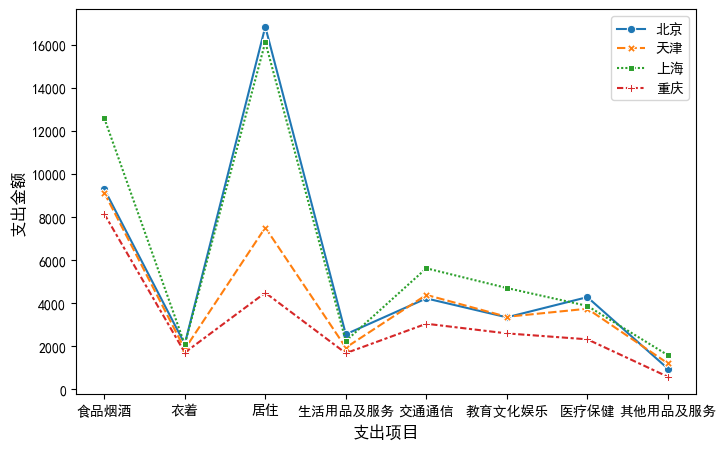

In [39]:
### 绘制平行坐标图
df=pd.read_csv('shu4.csv')
plt.rcParams['font.sans-serif'] = ['SimHei']

plt.figure(figsize=(8, 5))
dfs=[df['北京'],df['天津'],df['上海'],df['重庆']]
sns.lineplot(data=dfs,markers=True)
plt.xlabel('支出项目',size=12)
plt.ylabel('支出金额',size=12)
plt.xticks(range(8),df['支出项目'])  # 添加x轴标签


### 绘制雷达图

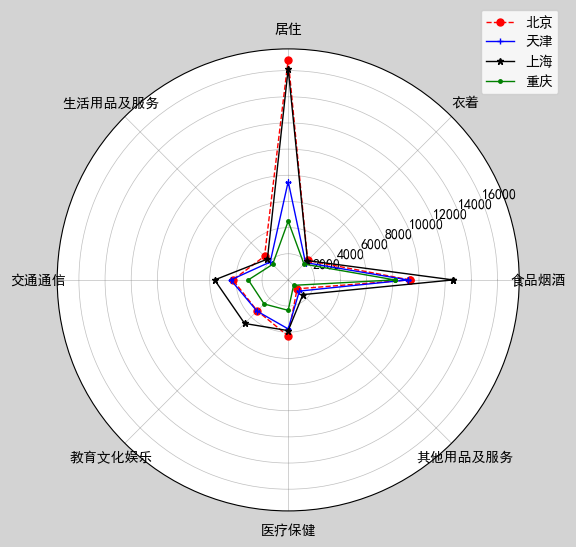

In [41]:
# ## 绘制雷达图
import numpy as np
plt.rcParams['font.sans-serif'] = ['SimHei']
df=pd.read_csv('shu4.csv')
labels=np.array(df['支出项目'])  # 设置标签
datalenth=8                      # 数据长度
df1=np.array(df['北京']);df2=np.array(df['天津'])
df3=np.array(df['上海']);df4=np.array(df['重庆'])
angles=np.linspace(0,2*np.pi,datalenth,endpoint=False)
df1=np.concatenate((df1,[df1[0]]))  # 使雷达图闭合
df2=np.concatenate((df2,[df2[0]]))
df3=np.concatenate((df3,[df3[0]]))
df4=np.concatenate((df4,[df4[0]]))
angles=np.concatenate((angles,[angles[0]]))
plt.figure(figsize=(6,6),facecolor='lightgray')     # 画布背景色
plt.polar(angles,df1,'r--',linewidth=1,marker='o',markersize=5,label='北京') # 红色虚线
plt.polar(angles,df2,'b',linewidth=1,marker='+',markersize=5,label='天津')   # 蓝色实线
plt.polar(angles,df3,'k',linewidth=1,marker='*',markersize=5,label='上海')   # 黑色实线
plt.polar(angles,df4,'g',linewidth=1,marker='.',markersize=5,label='重庆')   # 绿色实线
plt.thetagrids(range(0,360,45),labels)                       # 设置标签
plt.grid(linestyle='-',linewidth=0.5,color='gray',alpha=0.5) # 设置网格线
plt.legend(loc='upper right',bbox_to_anchor=(1.1,1.1))       # 绘制图例并设置图例位置

plt.show()

python例子

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv('shu7.csv')
df.info()
df.describe()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   性别      60 non-null     object
 1   家庭所在地   60 non-null     object
 2   月生活费支出  60 non-null     int64 
dtypes: int64(1), object(2)
memory usage: 1.5+ KB


,性别,家庭所在地,月生活费支出
0,女,中小城市,2535
1,男,大型城市,3520
2,男,大型城市,3042
3,女,中小城市,2704
4,女,中小城市,3380


数据

<Axes: xlabel='月生活费支出', ylabel='Density'>

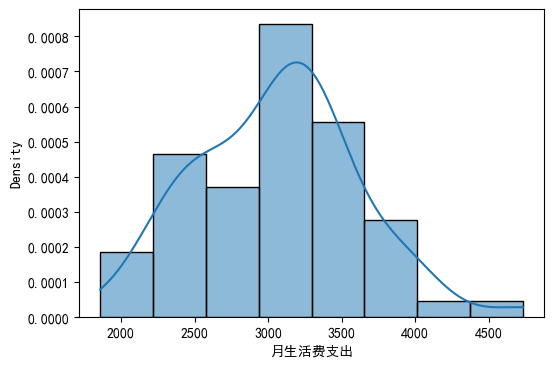

In [45]:
# 绘制全60 名大学生月生活费支出的直方图

plt.rcParams['font.sans-serif'] = ['SimHei']
fig = plt.figure(figsize=(6, 4))
sns.histplot(df['月生活费支出'],bins=8,kde=True,stat="density")

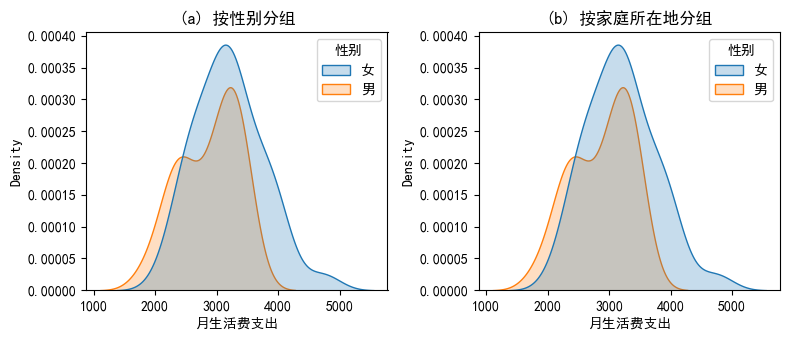

In [76]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.figure(figsize=(8, 3.5))
plt.subplot(1,2,1)
sns.kdeplot(df,x='月生活费支出',hue='性别',fill=True)  #新版本将shade=True改为fill=True
plt.title('(a) 按性别分组')
plt.subplot(1,2,2)
sns.kdeplot(df,x='月生活费支出',hue='性别',fill=True)
plt.title('(b) 按家庭所在地分组')  
plt.tight_layout()
plt.show()


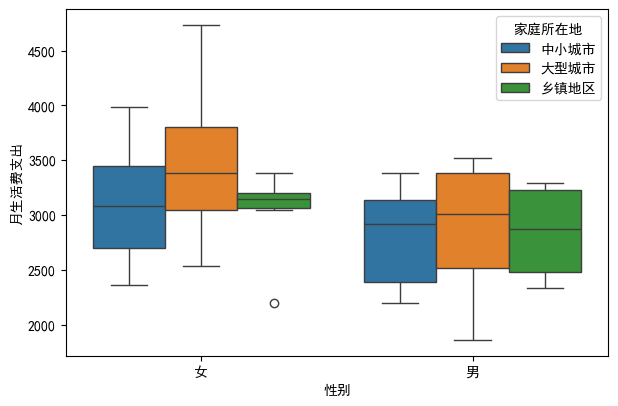

In [78]:
# 绘制按性别和家庭所在地分组的月生活费支出的箱线图

plt.rcParams['font.sans-serif'] = ['SimHei']  # 显示中文
plt.figure(figsize=(7, 4.5))
sns.boxplot(x='性别', y="月生活费支出", hue='家庭所在地', data=df)

plt.show()

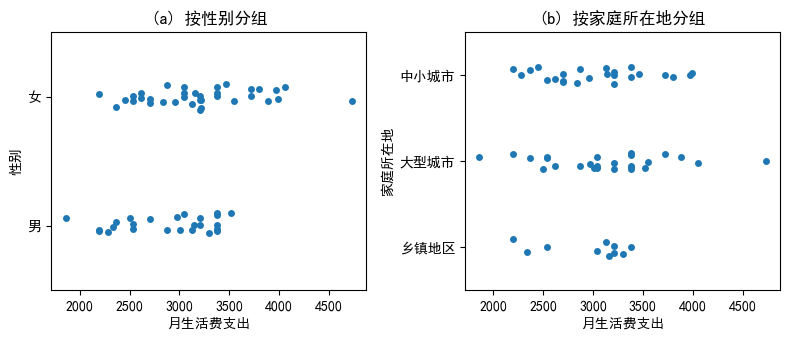

In [47]:
plt.rcParams['font.sans-serif'] = ['SimHei']

plt.subplots(1,2,figsize=(8, 3.5))
plt.subplot(121)
sns.stripplot(x='月生活费支出',y='性别',jitter=True, size=5,data=df)
plt.title('(a) 按性别分组')

plt.subplot(122)
sns.stripplot(x='月生活费支出',y='家庭所在地',size=5,data=df)
plt.title('(b) 按家庭所在地分组')

plt.tight_layout()
plt.show()

In [49]:
# 概括性描述
import pandas as pd

desc=df.describe(include=None)  # 不包括类别变量
round(desc,2)

,月生活费支出
count,60.00
mean,3061.97
std,548.08
min,1859.00
25%,2620.00
50%,3127.00
75%,3380.00
max,4732.00


In [51]:
# 按性别和家庭所在地分组计算描述统计量
tab = pd.pivot_table(df,index=['性别','家庭所在地'],values=['月生活费支出'],
                     margins=True, margins_name='合计',
                     aggfunc=['sum', 'min', 'max', 'median', 'mean', 'std'])   
                                        # 计算总和、最小值和最大值、中位数、平均数和标准差
round(tab,2)

sum    min    max  median     mean     std
          月生活费支出 月生活费支出 月生活费支出  月生活费支出   月生活费支出  月生活费支出
性别 家庭所在地                                               
女  中小城市    56012   2366   3988  3084.0  3111.78  522.15
   乡镇地区    18118   2197   3380  3143.5  3019.67  418.41
   大型城市    37772   2535   4732  3380.0  3433.82  648.19
男  中小城市    16833   2197   3380  2915.5  2805.50  490.29
   乡镇地区    11377   2335   3296  2873.0  2844.25  480.82
   大型城市    43606   1859   3520  3008.0  2907.07  506.77
合计        183718   1859   4732  3127.0  3061.97  548.08

In [80]:
# 按性别和家庭所在地分组计算描述统计量
import pandas as pd

# 编写函数
def my_summary(df, col=['性别']):
    df_res = pd.DataFrame()
    df_res['n'] = df.groupby(col)['月生活费支出'].count()
    df_res['平均数'] = df.groupby(col)['月生活费支出'].mean().round(3)
    df_res['中位数'] = df.groupby(col)['月生活费支出'].median()
    df_res['标准差'] = df.groupby(col)['月生活费支出'].std().round(4)
    df_res['全距'] = df.groupby(col)['月生活费支出'].apply(lambda x: x.max()-x.min())
    df_res['变异系数'] = df.groupby(col)['月生活费支出'].apply(lambda x: x.std()/x.mean())
    df_res['偏度系数'] = df.groupby(col)['月生活费支出'].skew()
    #df_res['峰度系数'] = df.groupby(col)['月生活费支出'].kurtosis()
    return df_res

# 按性别分组计算统计量
df1=my_summary(df, ['性别'])  
print('按性别分组')
round(df1,4)

按性别分组


,n,平均数,中位数,标准差,全距,变异系数,偏度系数
性别,,,,,,,
女,35,3197.20,3210.0,559.6233,2535,0.1750,0.5022
男,25,2872.64,3008.0,480.4089,1661,0.1672,-0.4741


In [78]:
import pandas as pd

def my_summary(df, col=['性别']):
    df_res = pd.DataFrame()
    grouped = df.groupby(col)['月生活费支出']
    df_res['n'] = grouped.count()
    df_res['平均数'] = grouped.mean().round(3)
    df_res['中位数'] = grouped.median()
    df_res['标准差'] = grouped.std().round(4)
    df_res['全距'] = grouped.apply(lambda x: x.max() - x.min())
    df_res['变异系数'] = grouped.apply(lambda x: x.std() / x.mean())
    df_res['偏度系数'] = grouped.skew()
    #df_res['峰度系数'] = grouped.kurtosis() 
    return df_res
    
# 按性别分组计算统计量
df1=my_summary(df, ['性别'])  
print('按性别分组')
round(df1,4)

按性别分组


,n,平均数,中位数,标准差,全距,变异系数,偏度系数
性别,,,,,,,
女,35,3197.20,3210.0,559.6233,2535,0.1750,0.5022
男,25,2872.64,3008.0,480.4089,1661,0.1672,-0.4741


In [82]:
# 按家庭所在地分组计算统计量
df2=my_summary(df, ['家庭所在地'])
print('按家庭所在地分组')
round(df2,4)

按家庭所在地分组


,n,平均数,中位数,标准差,全距,变异系数,偏度系数
家庭所在地,,,,,,,
中小城市,24,3035.208,3042.5,521.6586,1791,0.1719,0.2688
乡镇地区,10,2949.500,3143.5,427.2302,1183,0.1448,-0.9908
大型城市,26,3129.923,3126.5,618.3162,2873,0.1975,0.2966


In [84]:
# 按性别和家庭所在地交叉分组计算统计量
df3=my_summary(df, ['性别', '家庭所在地'])
print('按性别和家庭所在地交叉分组')
round(df3,4)

按性别和家庭所在地交叉分组


n       平均数     中位数       标准差    全距    变异系数    偏度系数
性别 家庭所在地                                                      
女  中小城市   18  3111.778  3084.0  522.1485  1622  0.1678  0.3447
   乡镇地区    6  3019.667  3143.5  418.4078  1183  0.1386 -2.0431
   大型城市   11  3433.818  3380.0  648.1935  2197  0.1888  0.5159
男  中小城市    6  2805.500  2915.5  490.2949  1183  0.1748 -0.2763
   乡镇地区    4  2844.250  2873.0  480.8169   961  0.1690 -0.1207
   大型城市   15  2907.067  3008.0  506.7739  1661  0.1743 -0.6972